In [ ]:
import pandas as pd

df = pd.read_csv('farm_sustainability_data.csv')
print(df.head())

     month           farm_id  hectares  water_used_liters  fertilizer_n_kg  \
0  2024-01  GreenValley Farm     156.2           226509.0           1693.4   
1  2024-02  GreenValley Farm     156.2           253997.0           1696.7   
2  2024-03  GreenValley Farm     156.2           241437.0           1855.1   
3  2024-04  GreenValley Farm     156.2           233390.0           1785.2   
4  2024-05  GreenValley Farm     156.2           212229.0           1570.3   

   fertilizer_p_kg  fertilizer_k_kg  waste_generated_kg  waste_recycled_kg  \
0            571.0            636.9              2810.2              823.2   
1            585.7            754.5              2968.5             1002.0   
2            626.2            709.6              2992.3             1131.8   
3            565.0            652.3              3032.0             1094.4   
4            564.2            678.3              2824.3              892.3   

   fuel_used_liters  electricity_kwh  crop_yield_kg  
0       

In [ ]:
# Check dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (72, 12)

Column Names:
Index(['month', 'farm_id', 'hectares', 'water_used_liters', 'fertilizer_n_kg',
       'fertilizer_p_kg', 'fertilizer_k_kg', 'waste_generated_kg',
       'waste_recycled_kg', 'fuel_used_liters', 'electricity_kwh',
       'crop_yield_kg'],
      dtype='object')

Data Types:
month                  object
farm_id                object
hectares              float64
water_used_liters     float64
fertilizer_n_kg       float64
fertilizer_p_kg       float64
fertilizer_k_kg       float64
waste_generated_kg    float64
waste_recycled_kg     float64
fuel_used_liters      float64
electricity_kwh       float64
crop_yield_kg         float64
dtype: object

Missing Values:
month                 0
farm_id               0
hectares              0
water_used_liters     0
fertilizer_n_kg       0
fertilizer_p_kg       0
fertilizer_k_kg       0
waste_generated_kg    0
waste_recycled_kg     0
fuel_used_liters      0
electricity_kwh       0
crop_yield_kg         0
dtype: in

In [ ]:
# Remove duplicates
df = df.drop_duplicates()

# Fill missing values with 0
df = df.fillna(0)

print("Data cleaned successfully!")

Data cleaned successfully!


In [ ]:
print("Total Water Used (Liters):", df['water_used_liters'].sum())

print("Total Nitrogen Fertilizer (kg):", df['fertilizer_n_kg'].sum())

print("Total Phosphorus Fertilizer (kg):", df['fertilizer_p_kg'].sum())

print("Total Potassium Fertilizer (kg):", df['fertilizer_k_kg'].sum())

print("Total Waste Generated (kg):", df['waste_generated_kg'].sum())

Total Water Used (Liters): 12556813.0
Total Nitrogen Fertilizer (kg): 77194.4
Total Phosphorus Fertilizer (kg): 38127.5
Total Potassium Fertilizer (kg): 37559.9
Total Waste Generated (kg): 213256.5


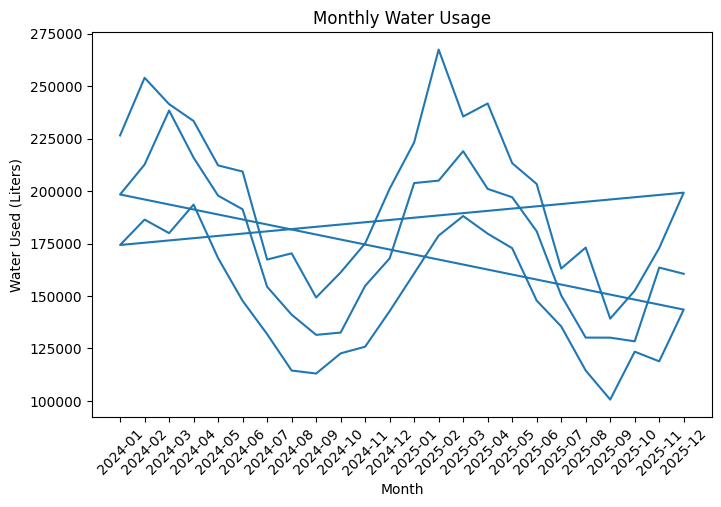

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(df['month'], df['water_used_liters'])
plt.title("Monthly Water Usage")
plt.xlabel("Month")
plt.ylabel("Water Used (Liters)")
plt.xticks(rotation=45)
plt.show()

In [ ]:
print(df.columns.tolist())

['month', 'farm_id', 'hectares', 'water_used_liters', 'fertilizer_n_kg', 'fertilizer_p_kg', 'fertilizer_k_kg', 'waste_generated_kg', 'waste_recycled_kg', 'fuel_used_liters', 'electricity_kwh', 'crop_yield_kg']


In [ ]:
# CO2 emission factors

fuel_emissions = df['fuel_used_liters'] * 2.68   # kg CO2 per liter diesel
electricity_emissions = df['electricity_kwh'] * 0.82  # kg CO2 per kWh

df['estimated_co2_kg'] = fuel_emissions + electricity_emissions

print("Total CO2 Emissions (kg):")
print(round(df['estimated_co2_kg'].sum(), 2))

Total CO2 Emissions (kg):
715259.4


In [ ]:
total_water = df['water_used_liters'].sum()

total_fertilizer = (
    df['fertilizer_n_kg'].sum() +
    df['fertilizer_p_kg'].sum() +
    df['fertilizer_k_kg'].sum()
)

total_waste = df['waste_generated_kg'].sum()
total_recycled = df['waste_recycled_kg'].sum()

total_yield = df['crop_yield_kg'].sum()

print("Total Water Used:", round(total_water,2))
print("Total Fertilizer Used:", round(total_fertilizer,2))
print("Total Crop Yield:", round(total_yield,2))

Total Water Used: 12556813.0
Total Fertilizer Used: 152881.8
Total Crop Yield: 5992529.0


In [ ]:
water_efficiency = total_yield / total_water

print("Water Efficiency:")
print(round(water_efficiency,4), "kg crop per liter water")

Water Efficiency:
0.4772 kg crop per liter water


In [ ]:
fertilizer_efficiency = total_yield / total_fertilizer

print("Fertilizer Efficiency:")
print(round(fertilizer_efficiency,4), "kg crop per kg fertilizer")

Fertilizer Efficiency:
39.1971 kg crop per kg fertilizer


In [ ]:
recycling_rate = (total_recycled / total_waste) * 100

print("Recycling Rate:")
print(round(recycling_rate,2), "%")

Recycling Rate:
40.92 %


In [ ]:
water_score = min(water_efficiency * 100, 100)
fertilizer_score = min(fertilizer_efficiency * 10, 100)
waste_score = recycling_rate

sustainability_score = (
    water_score +
    fertilizer_score +
    waste_score
) / 3

print("Sustainability Score:")
print(round(sustainability_score,2), "/100")

Sustainability Score:
62.88 /100


In [ ]:
summary = {
    "Metric": [
        "Water Used",
        "Fertilizer Used",
        "Waste Generated",
        "Waste Recycled",
        "Crop Yield",
        "CO2 Emissions",
        "Sustainability Score"
    ],
    "Value": [
        round(total_water,2),
        round(total_fertilizer,2),
        round(total_waste,2),
        round(total_recycled,2),
        round(total_yield,2),
        round(df['estimated_co2_kg'].sum(),2),
        round(sustainability_score,2)
    ]
}

import pandas as pd
summary_df = pd.DataFrame(summary)

summary_df

,Metric,Value
0,Water Used,12556813.00
1,Fertilizer Used,152881.80
2,Waste Generated,213256.50
3,Waste Recycled,87266.00
4,Crop Yield,5992529.00
5,CO2 Emissions,715259.40
6,Sustainability Score,62.88


In [ ]:
!pip install -q google-generativeai

In [ ]:
import google.generativeai as genai

/usr/local/lib/python3.12/dist-packages/google/colab/_import_hooks/_hook_injector.py:55: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  loader.exec_module(module)


In [ ]:
genai.configure(api_key="AQ.Ab8RN6JEEbFz37jo0qhZRzIndamA1S13gl5WhjMD-CFxAczKuQ")

In [ ]:
model = genai.GenerativeModel("gemini-2.5-flash")

In [ ]:
prompt = f"""
You are an environmental sustainability expert.

Analyze the following farm sustainability metrics and generate a professional report.

Farm Sustainability Metrics

Water Used: {round(total_water,2)} Liters

Fertilizer Used: {round(total_fertilizer,2)} kg

Waste Generated: {round(total_waste,2)} kg

Waste Recycled: {round(total_recycled,2)} kg

Crop Yield: {round(total_yield,2)} kg

Estimated CO2 Emissions: {round(df['estimated_co2_kg'].sum(),2)} kg

Sustainability Score: {round(sustainability_score,2)}

Generate:

1. Executive Summary

2. Performance Analysis

3. Environmental Impact

4. Strengths

5. Weaknesses

6. Recommendations

7. Conclusion

Write the report professionally.
"""

response = model.generate_content(prompt)

print(response.text)

## Farm Sustainability Report

**Date:** October 26, 2023
**Prepared For:** [Farm Management/Stakeholders]
**Prepared By:** [Environmental Sustainability Expert]

---

### 1. Executive Summary

This report provides an in-depth analysis of the farm's sustainability performance based on the provided metrics. The farm currently holds a **Sustainability Score of 62.88**, indicating a commitment to sustainable practices but also highlighting significant opportunities for improvement. The farm demonstrates exceptional water use efficiency relative to its high crop yield, which is a commendable strength. However, the absolute volumes of water used, fertilizer applied, waste generated, and estimated CO2 emissions are substantial, necessitating strategic interventions to enhance environmental stewardship and operational efficiency. Moving forward, a targeted approach focusing on resource optimization, waste reduction, and decarbonization will be crucial for elevating the farm's overall sustaina

In [ ]:
!pip install reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 21.5 MB/s eta 0:00:00


In [ ]:
from reportlab.platypus import SimpleDocTemplate, Paragraph
from reportlab.lib.styles import getSampleStyleSheet

doc = SimpleDocTemplate("Sustainability_Report.pdf")
styles = getSampleStyleSheet()

story = []

story.append(Paragraph("<b>AI-Powered Sustainability Report</b>", styles['Title']))
story.append(Paragraph(response.text.replace("\n","<br/>"), styles['BodyText']))

doc.build(story)

print("PDF Generated Successfully!")

PDF Generated Successfully!


In [ ]:
from google.colab import files

files.download("Sustainability_Report.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>